# Forest Cover Type Prediction using XGBoost: A Comprehensive Machine Learning Pipeline

## 1. Introduction & Problem Statement
In this notebook, we tackle a classic, large-scale multiclass classification problem: predicting the **Forest Cover Type** of 30x30 meter cells in the Roosevelt National Forest of Northern Colorado. Instead of relying on direct imagery, our model will use purely cartographic variables (such as elevation, slope, and soil type) to deduce the ecological landscape. 

This is a **supervised multiclass classification task**, where the goal is to map a given set of environmental features $X$ to one of 7 distinct forest cover classes $y \in \{0, 1, ..., 6\}$.

## 2. The Dataset & Main Challenges
We are using the `fetch_covtype` dataset from Scikit-Learn. It contains **581,012 observations** and **54 features** (10 continuous, like elevation and distance to hydrology, and 44 one-hot encoded categorical variables for wilderness areas and soil types).

Solving this problem effectively requires addressing two major challenges:
1. **Extreme Class Imbalance:** The dataset is heavily skewed. Lodgepole Pine and Spruce/Fir classes account for roughly 85% of the data, while the rarest class (Cottonwood/Willow) makes up less than 0.5%. A naive model would simply learn to predict the majority classes. We will counter this using calculated **sample weights** and optimizing for the **Macro F1-Score**.
2. **Computational Scale:** With over half a million rows, standard decision tree algorithms can be prohibitively slow. We will utilize histogram-based binning to drastically speed up the training process without sacrificing accuracy.

## 3. Theoretical Foundation: Why XGBoost?
To solve this, we will use **XGBoost (eXtreme Gradient Boosting)**. XGBoost is an optimized distributed gradient boosting library designed to be highly efficient, flexible, and portable. 

### Intuition
Unlike a Random Forest that builds many independent trees and averages them, Gradient Boosting builds trees **sequentially**. Each new tree is designed to correct the errors (residuals) made by the ensemble of all previous trees. Imagine a team of workers where the first worker does their best to complete a task, the second worker focuses exclusively on fixing the first worker's mistakes, the third fixes the second's, and so on.

### The Mathematics
At a given step $t$, the model's prediction for an instance $i$ is the sum of predictions from all previous trees plus the new tree $f_t$:

$$ \hat{y}_i^{(t)} = \sum_{k=1}^t f_k(x_i) = \hat{y}_i^{(t-1)} + f_t(x_i) $$

To find the optimal new tree $f_t$, XGBoost minimizes the following **Objective Function**:

$$ \mathcal{L}^{(t)} = \sum_{i=1}^n l(y_i, \hat{y}_i^{(t-1)} + f_t(x_i)) + \Omega(f_t) $$

Where:
* $l$ is a differentiable convex loss function (in our case, multinomial logistic loss) that measures the difference between the target $y_i$ and the current prediction.
* $\Omega(f_t)$ is the **regularization term** that penalizes model complexity to prevent overfitting:

$$ \Omega(f) = \gamma T + \frac{1}{2}\lambda \sum_{j=1}^T w_j^2 $$

Here, $T$ is the number of leaves in the tree, $w_j$ represents the leaf weights (scores), $\gamma$ controls the minimum loss reduction required to make a split, and $\lambda$ is the L2 regularization term on leaf weights. XGBoost uses a second-order Taylor expansion (incorporating both gradients and Hessians) to quickly find the optimal splits.

## 4. Pipeline & Tools
To build a robust and interpretable solution, we will move through the following stages:
* **Exploratory Data Analysis (EDA):** Using `Pandas`, `Matplotlib`, and `Seaborn` to understand feature distributions and correlations.
* **Feature Engineering:** Deriving new, non-linear geometric features (like Euclidean distances) to help our decision trees split the data more efficiently.
* **Model Training & Hyperparameter Tuning:** Utilizing `Optuna` for advanced Bayesian optimization to find the perfect architecture for our XGBoost classifier.
* **Model Explainability:** Opening the "black box" using `SHAP` (Shapley Additive exPlanations) based on cooperative game theory, allowing us to understand exactly how much each feature contributed to a specific prediction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import classification_report, f1_score
from sklearn.utils.class_weight import compute_sample_weight
import optuna
import shap
import gc

In [2]:
covtype = fetch_covtype()

df = pd.DataFrame(covtype.data, columns=covtype.feature_names)
df['Cover_Type'] = covtype.target
df = df.drop_duplicates()

## 2. Exploratory Data Analysis (EDA)

Before feeding data into an algorithm, we must understand its structural characteristics, quality, and statistical properties. This cell performs a comprehensive EDA specifically tailored to guide our decisions for tree-based models like XGBoost.

### What are we analyzing?

1. **Basic Data Health (Missing Values & Duplicates):** 
   We check the fundamental shape of the data. Because this dataset represents physical 30x30 meter grid cells, identical adjacent grid patches can result in duplicate rows. Recognizing this is crucial to prevent *data leakage* later when we split the data into training and testing sets.

2. **Target Class Distribution:** 
   By plotting the frequency of each `Cover_Type`, we expose the severe **class imbalance**. 
   * *Algorithm Intuition:* If a model simply predicts "Lodgepole Pine" (the majority class) every time, it would achieve high overall accuracy but fail entirely at predicting rare classes like "Cottonwood/Willow". This visual confirms that we will need to calculate **sample weights** and use the **Macro F1-Score** to force the model to care about minority classes.

3. **Continuous Variables & Correlations:** 
   We generate summary statistics, a correlation heatmap, and class-separated boxplots (using a 100k random sample for computational efficiency).
   * *Algorithm Intuition:* Unlike linear regression or Neural Networks, Decision Trees **do not require feature scaling or normalization** because they split data using ordinal thresholds (e.g., `Elevation > 2500`). Furthermore, they are highly robust to **multicollinearity**. However, identifying strongly correlated features (like `Hillshade_9am` and `Hillshade_3pm`) provides excellent hints for our next step: Feature Engineering.

4. **Categorical Features (Reversing One-Hot Encoding):** 
   The dataset provides Wilderness Areas and Soil Types in a One-Hot Encoded (OHE) format. To analyze them, we temporarily reverse this encoding using `idxmax()`. 
   * We specifically hunt for **rare soil types** (occurring in less than 0.1% of the dataset). 
   * *Algorithm Intuition:* Extremely rare categorical traits can lead to overfitting, as a tree might create a highly specific split (a leaf node) for just a handful of observations. Recognizing these rare categories tells us that we must carefully tune XGBoost's `min_child_weight` parameter, which dictates the minimum sum of instance weights required in a child node, effectively pruning these overly specific branches.


--- Basic Information ---
Rows: 581012, Columns: 55
Missing values: 0
Duplicates: 0

--- Class Distribution (Targets) ---
Cover_Type
1    36.46 %
2    48.76 %
3     6.15 %
4     0.47 %
5     1.63 %
6     2.99 %
7     3.53 %
Name: proportion, dtype: object


C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_6148\2310317382.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_eda, x='Cover_Type', palette='viridis')


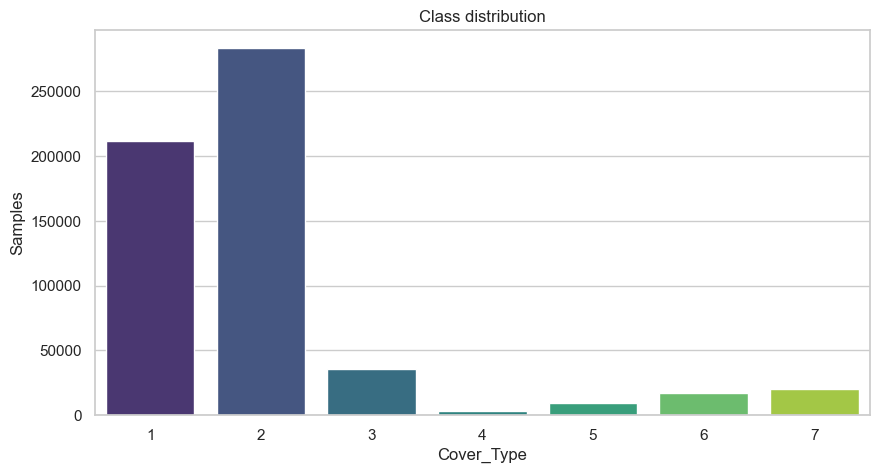


--- Continuous Variables  ---


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
count,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00
mean,2959.37,155.66,14.10,269.43,46.42,2350.15,212.15,223.32,142.53,1980.29
std,279.98,111.91,7.49,212.55,58.30,1559.25,26.77,19.77,38.27,1324.20
min,1859.00,0.00,0.00,0.00,-173.00,0.00,0.00,0.00,0.00,0.00
25%,2809.00,58.00,9.00,108.00,7.00,1106.00,198.00,213.00,119.00,1024.00
50%,2996.00,127.00,13.00,218.00,30.00,1997.00,218.00,226.00,143.00,1710.00
75%,3163.00,260.00,18.00,384.00,69.00,3328.00,231.00,237.00,168.00,2550.00
max,3858.00,360.00,66.00,1397.00,601.00,7117.00,254.00,254.00,254.00,7173.00


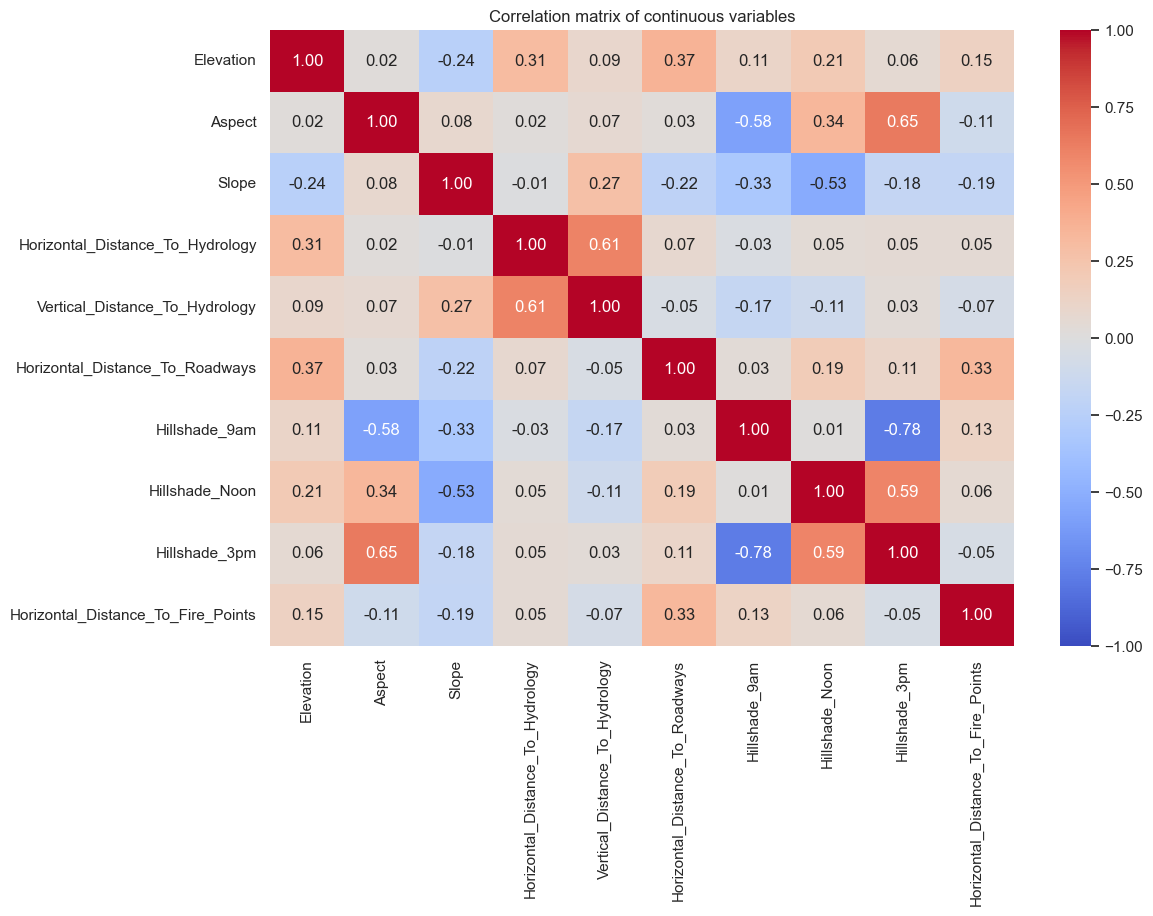

C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_6148\2310317382.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda_sample, x='Cover_Type', y=col, ax=axes[i], palette='muted')
C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_6148\2310317382.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda_sample, x='Cover_Type', y=col, ax=axes[i], palette='muted')
C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_6148\2310317382.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda_sample, x='Cover_Type', y=col, ax=

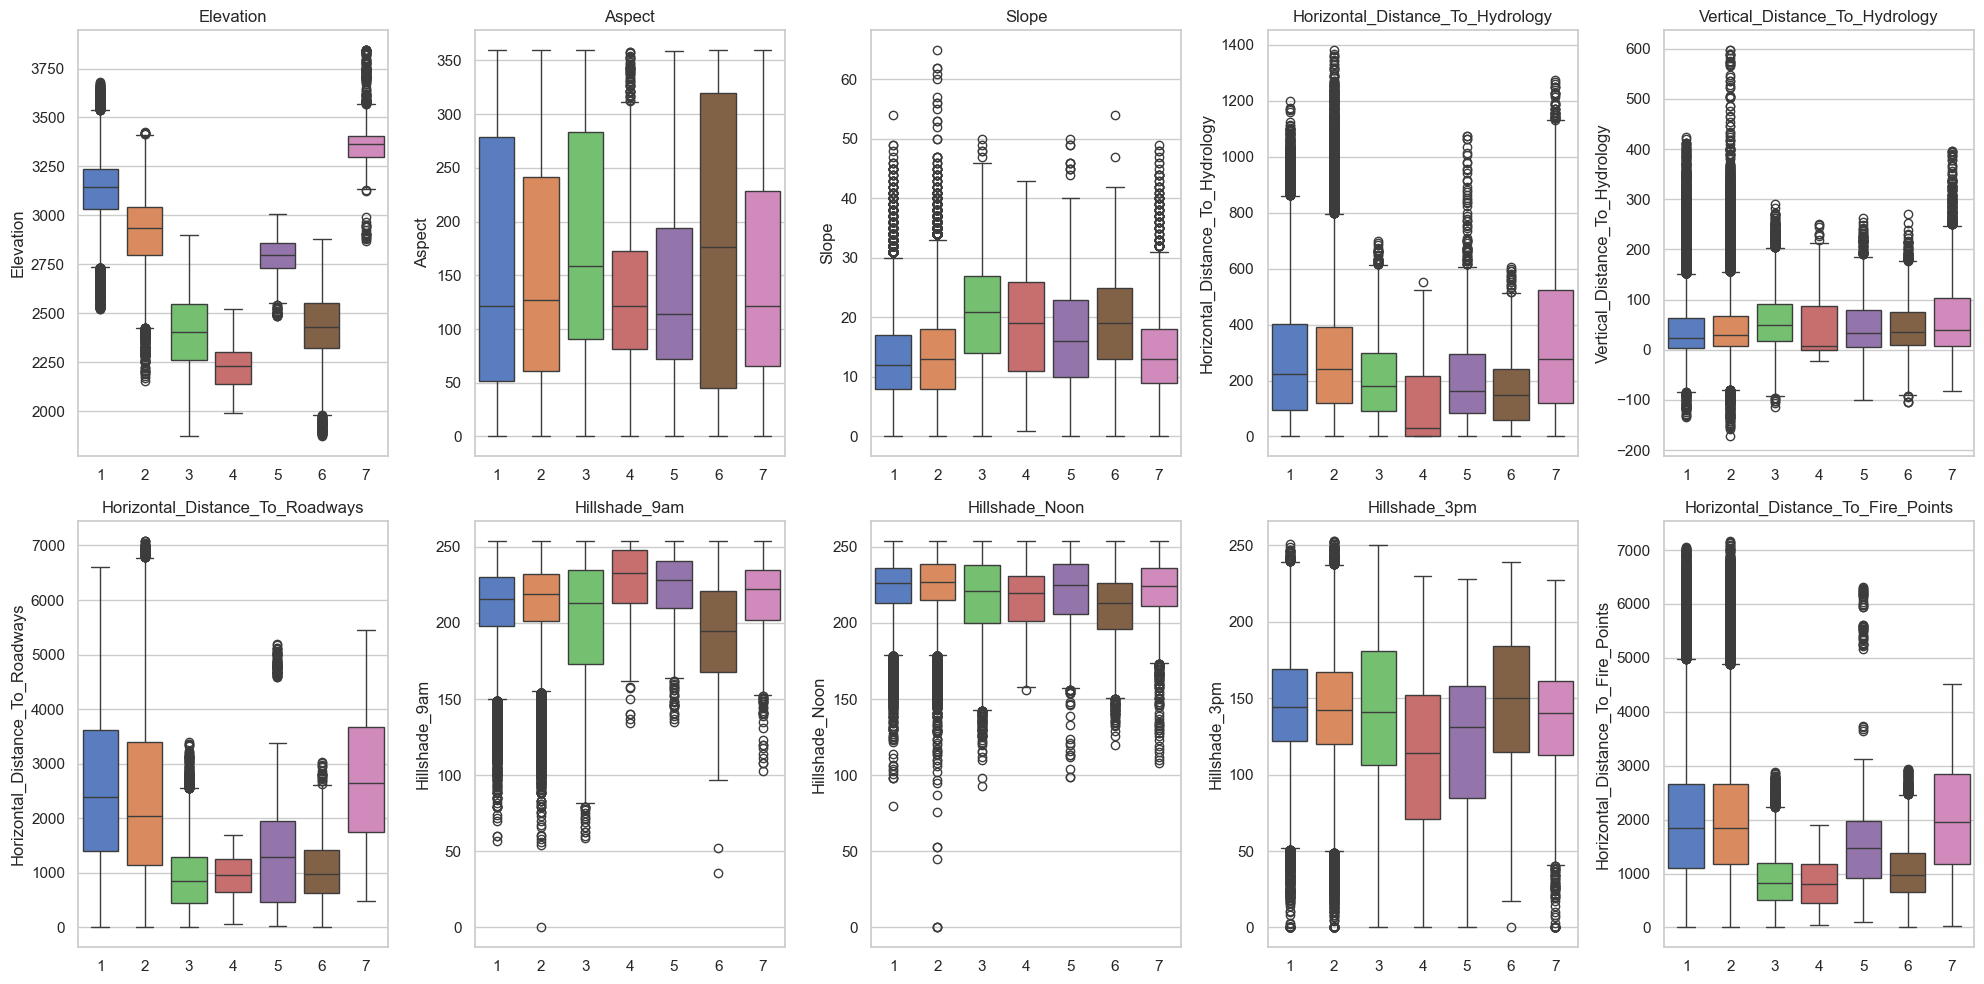


--- Analysing Land and Soil ---


C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_6148\2310317382.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_eda, x='Wilderness_Category', palette='Set2')


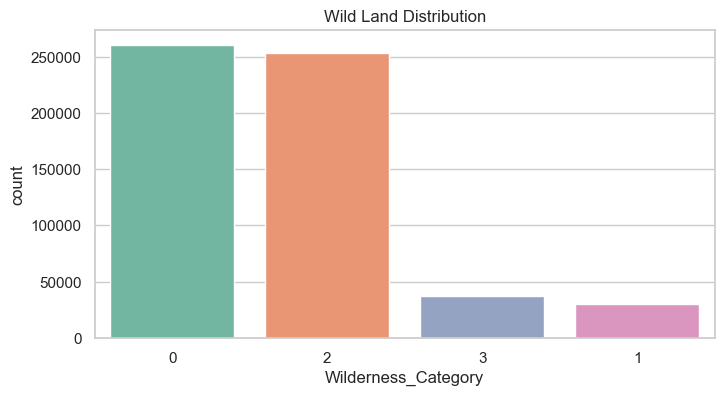

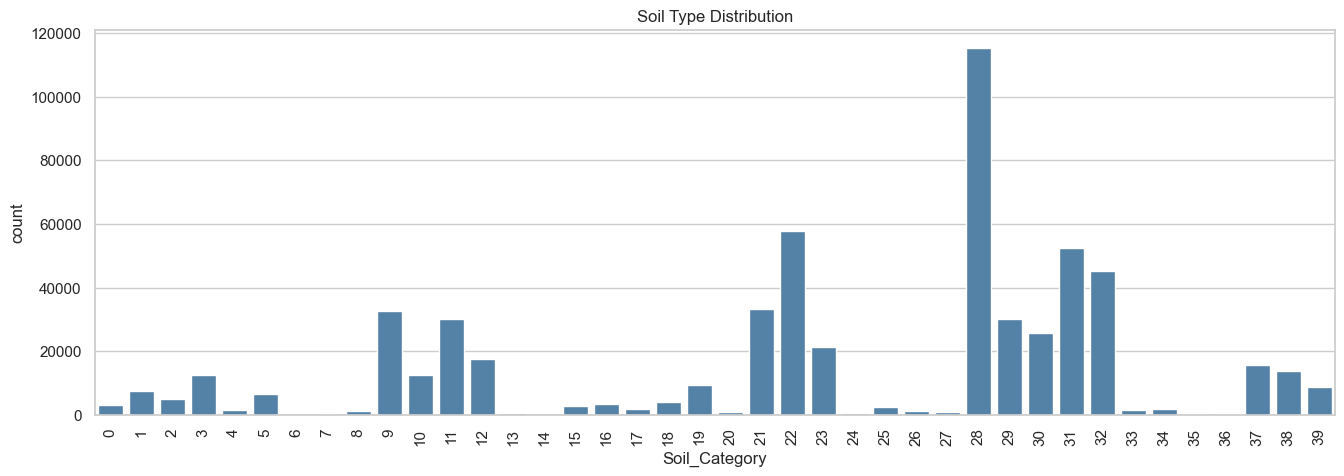

Amount of types of soil, being less than 0.01% of dataset: 6
[24, 36, 7, 35, 6, 14]


In [3]:
# Plot type
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

df = df.drop(columns=['Wilderness_Category', 'Soil_Category'], errors='ignore')

df_eda = df.copy()
df_eda = df_eda.drop(columns=['Wilderness_Category', 'Soil_Category'], errors='ignore')

# Grouping features
num_cols = df_eda.columns[:10].tolist()         # First 10 are numerical
wild_cols = [c for c in df_eda.columns if 'Wilderness_Area' in c]
soil_cols = [c for c in df_eda.columns if 'Soil_Type' in c]

print(f"\n--- Basic Information ---")
print(f"Rows: {df_eda.shape[0]}, Columns: {df_eda.shape[1]}")
print(f"Missing values: {df_eda.isnull().sum().sum()}")
print(f"Duplicates: {df_eda.duplicated().sum()}")

# 2. Class distribution
print("\n--- Class Distribution (Targets) ---")
class_dist = df_eda['Cover_Type'].value_counts(normalize=True).sort_index() * 100
print(class_dist.round(2).astype(str) + ' %')

plt.figure(figsize=(10, 5))
sns.countplot(data=df_eda, x='Cover_Type', palette='viridis')
plt.title('Class distribution')
plt.ylabel('Samples')
plt.show()

print("\n--- Continuous Variables  ---")
display(df_eda[num_cols].describe().round(2))

# Continuous variable distribution
plt.figure(figsize=(12, 8))
corr_matrix = df_eda[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation matrix of continuous variables')
plt.show()

# How does numerical variables behave for particular class?
# We use sample of 100k rows
df_eda_sample = df_eda.sample(n=100000, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df_eda_sample, x='Cover_Type', y=col, ax=axes[i], palette='muted')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

# Analysing categorical variables (Reverse One-Hot Encoding)
# We check which type of soil and wild lands dominate
print("\n--- Analysing Land and Soil ---")
df_eda['Wilderness_Category'] = df_eda[wild_cols].idxmax(axis=1).str.replace('Wilderness_Area_', '')
df_eda['Soil_Category'] = df_eda[soil_cols].idxmax(axis=1).str.replace('Soil_Type_', '').astype(int)

plt.figure(figsize=(8, 4))
sns.countplot(data=df_eda, x='Wilderness_Category', palette='Set2')
plt.title('Wild Land Distribution')
plt.show()

plt.figure(figsize=(16, 5))
sns.countplot(data=df_eda, x='Soil_Category', color='steelblue')
plt.title('Soil Type Distribution')
plt.xticks(rotation=90)
plt.show()

# Looking for rare types of soil
soil_freq = df_eda['Soil_Category'].value_counts(normalize=True)
rare_soils = soil_freq[soil_freq < 0.001]
print(f"Amount of types of soil, being less than 0.01% of dataset: {len(rare_soils)}")
print(rare_soils.index.tolist())

## 3. Data Preprocessing & Feature Engineering

With a solid understanding of our data's landscape, we now prepare it for the XGBoost algorithm. This phase involves cleaning the data, explicitly defining complex relationships, and strictly structuring the target variable.

### Key Operations & Intuitions

1. **Deduplication (`drop_duplicates`):**
   In our EDA, we noted the presence of identical rows (likely due to the spatial grid nature of the data). We must drop these before splitting the data to prevent **Data Leakage**. If an identical observation exists in both the training and testing sets, the model would simply memorize the answer, leading to an artificially inflated test score that wouldn't hold up in production.

2. **Feature Engineering (The Math of Trees):**
   *Why engineer features if XGBoost is so powerful?* 
   Decision trees create **axis-aligned (orthogonal) splits**. This means a tree can easily say "Is Feature A > 10?", but it struggles to capture diagonal or complex relationships like "Is Feature A + Feature B > 10?". To approximate a diagonal boundary, a tree requires many deep, jagged, staircase-like splits. 
   By explicitly calculating these mathematical interactions, we allow the tree to capture complex geometry with a single split:
   * **Euclidean Distance:** We use the Pythagorean theorem ($c = \sqrt{a^2 + b^2}$) to calculate the direct `Distance_To_Hydrology` using the horizontal and vertical distances.
   * **Linear Combinations:** We calculate differences and averages for Elevation, Hillshade (sunlight), and Amenities (roads/fire points). This directly exposes relationships like "relative elevation to water" and "shift in shadow from morning to afternoon".

3. **Target Variable Shift (`y - 1`):**
   The original Cover Type classes are labeled from 1 to 7. However, XGBoost's `multi:softmax` objective mathematically requires class labels to be strictly zero-indexed (starting from 0 up to `num_class - 1`). Subtracting 1 aligns our target variable with the algorithm's internal C++ matrix expectations.

4. **Stratified Train-Test Split:**
   We split the data into 80% training and 20% testing. Crucially, we use `stratify=y`. Because our classes are severely imbalanced, a purely random split could result in the test set containing zero instances of the rarest classes. Stratification guarantees that the exact class proportions (e.g., Class 4 being ~0.5%) are perfectly preserved in both the training and testing sets.

In [4]:
df['Distance_To_Hydrology'] = np.sqrt(
    df['Horizontal_Distance_To_Hydrology']**2 + df['Vertical_Distance_To_Hydrology']**2
)
df['Elevation_Minus_Vertical_Hydrology'] = df['Elevation'] - df['Vertical_Distance_To_Hydrology']
df['Elevation_Plus_Vertical_Hydrology'] = df['Elevation'] + df['Vertical_Distance_To_Hydrology']

df['Hillshade_9am_Minus_3pm'] = df['Hillshade_9am'] - df['Hillshade_3pm']
df['Hillshade_Noon_Minus_3pm'] = df['Hillshade_Noon'] - df['Hillshade_3pm']
df['Mean_Hillshade'] = (df['Hillshade_9am'] + df['Hillshade_Noon'] + df['Hillshade_3pm']) / 3

df['Mean_Distance_To_Amenities'] = (
    df['Horizontal_Distance_To_Fire_Points'] + df['Horizontal_Distance_To_Roadways']
) / 2

X = df.drop(columns=['Cover_Type'])
y = df['Cover_Type'] - 1

del df
if 'covtype' in locals():
    del covtype
gc.collect()

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15, stratify=y_temp, random_state=42)

## 4. Baseline Model Training & Evaluation

In this cell, we establish our baseline XGBoost model. Even though this is just a baseline, applying out-of-the-box settings to a massive, highly imbalanced dataset is a recipe for failure. We must configure the algorithm to respect the data's structure and scale.

### Key Algorithmic Configurations

1. **Handling Imbalance via Sample Weights:**
   Because our data is heavily skewed, a standard model would minimize its loss by aggressively predicting the majority classes (Class 0 and 1) and ignoring the rare ones. 
   * *The Solution:* We calculate an array of `sample_weights` using the 'balanced' heuristic. This assigns a weight to each observation inversely proportional to its class frequency. 
   * *Mathematical Intuition:* The standard XGBoost objective function sums the loss over all instances: $\mathcal{L} = \sum l(y_i, \hat{y}_i)$. By injecting weights, the loss becomes $\mathcal{L} = \sum w_i \cdot l(y_i, \hat{y}_i)$. If a rare "Cottonwood/Willow" tree ($w_i = high$) is misclassified, it incurs a massive penalty, forcing the algorithm to pay attention to minority classes.

2. **The `multi:softmax` Objective:**
   This tells XGBoost we are dealing with a multiclass problem and that we want the final output to be the predicted class index rather than a probability distribution. (If we wanted probabilities, we would use `multi:softprob`).

3. **High-Performance Tree Building (`tree_method='hist'`):**
   * *Algorithm Intuition:* The traditional way decision trees find the best split (the "exact greedy" algorithm) requires sorting all continuous feature values and evaluating every single data point as a potential split candidate. With ~400,000 training rows, this is computationally disastrous ($O(N \log N)$ per feature).
   * By setting `tree_method='hist'`, XGBoost discretizes (bins) continuous features into a fixed number of buckets (histograms) before building the tree. This reduces the split-finding complexity to merely searching through the bins, drastically accelerating training times with almost zero loss in accuracy.

4. **Evaluation Strategy:**
   We evaluate the model using Scikit-Learn's `classification_report`. 
   * *Warning:* Do not be fooled by high overall **Accuracy**. Look closely at the **Macro Average F1-Score**. The Macro F1 calculates the metric for each class independently and averages them equally, treating the 0.5% rare class exactly the same as the 48% majority class.

In [5]:
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=7,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train, y_train, 
    sample_weight=sample_weights,
    verbose=False
)

y_pred = xgb_model.predict(X_test)

print("Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

Classification Report:

              precision    recall  f1-score   support

           0     0.8446    0.8623    0.8533     31776
           1     0.9062    0.8112    0.8561     42495
           2     0.8708    0.9152    0.8924      5363
           3     0.7926    0.9369    0.8587       412
           4     0.4008    0.9740    0.5679      1424
           5     0.7196    0.9417    0.8158      2605
           6     0.8262    0.9870    0.8995      3077

    accuracy                         0.8496     87152
   macro avg     0.7658    0.9183    0.8205     87152
weighted avg     0.8644    0.8496    0.8530     87152



## 5. Feature Validation & Bayesian Hyperparameter Optimization

With our baseline model trained, we now evaluate which features are driving its decisions and proceed to squeeze out maximum performance by tuning the algorithm's hyperparameters.

### 1. Feature Importance (Validating our Engineering)
We first extract and plot `xgb_model.feature_importances_`. 
* *Algorithm Intuition:* By default, XGBoost measures feature importance using **Gain**. Gain represents the relative contribution of a feature to the model, calculated by taking each feature's contribution for each tree in the model. A higher gain implies the feature is more crucial for generating predictions. 
* If our feature engineering was successful, you should see our engineered variables (like calculated distances and shaded differences) ranking high on this plot. This proves that pre-calculating complex geometric relationships saves the tree from having to approximate them with dozens of inefficient splits.

### 2. Hyperparameter Tuning with Optuna
Decision trees have a notoriously high variance and are prone to overfitting. To generalize well to unseen data, we must tune the model's constraints. 

Instead of traditional Grid Search or Random Search, we use **Optuna**, a hyperparameter optimization framework based on **Bayesian Optimization** (specifically, the Tree-structured Parzen Estimator algorithm). 
* *Mathematical Intuition:* Grid search is "blind". Bayesian optimization, however, uses the results of past trials to build a probabilistic surrogate model of the objective function. It calculates the expected improvement of testing a new set of parameters, allowing it to intelligently "hunt" for the optimal configuration in a fraction of the time.

### The Hyperparameter Search Space:
* **`learning_rate` (often called $\eta$):** Shrinks the contribution of each new tree. A lower learning rate requires more trees to model the data but generally leads to better generalization. (Sampled on a log scale because changes near 0.01 matter much more than changes near 0.2).
* **`max_depth`:** The maximum depth of a tree. We allow deep trees (up to 15) because we have highly complex, interacting categorical features (like 40 soil types).
* **`subsample` & `colsample_bytree` (Stochastic Regularization):** Dictate the fraction of rows and columns (respectively) randomly sampled for each tree. This injects randomness into the boosting process, mitigating overfitting (similar to how a Random Forest operates).
* **`min_child_weight`:** A critical parameter for our rare classes. It defines the minimum sum of instance weights (Hessian) needed in a child node. If a split results in a leaf node with a weight sum below this threshold, the building process gives up on that split. This directly prevents the model from memorizing individual noisy samples (like a single tree of a rare soil type).

**The Objective:** Notice that our Optuna objective function returns the `f1_score(..., average='macro')`. We explicitly instruct the Bayesian optimizer to search for parameters that improve the model's ability to classify *all* classes equally, penalizing configurations that only perform well on the majority classes.

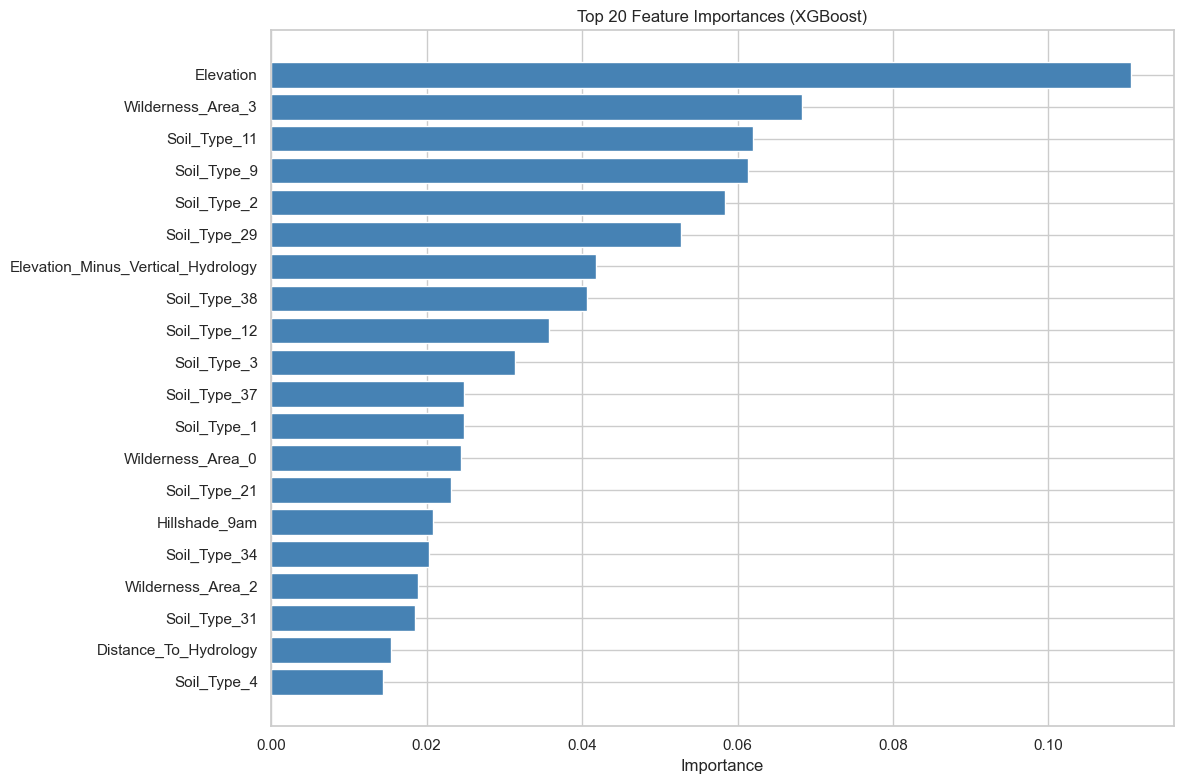

[I 2026-10-31 21:49:16,631] A new study created in memory with name: no-name-37498132-0e6e-48f4-a9be-e7ed7b530b3f
[I 2026-10-31 21:51:58,172] Trial 0 finished with value: 0.9352161199697563 and parameters: {'learning_rate': 0.21196916527652057, 'max_depth': 13, 'subsample': 0.5721014599312095, 'colsample_bytree': 0.8155622522440624, 'min_child_weight': 13}. Best is trial 0 with value: 0.9352161199697563.
[I 2026-10-31 22:01:59,589] Trial 1 finished with value: 0.8886011510037771 and parameters: {'learning_rate': 0.015847950180850046, 'max_depth': 11, 'subsample': 0.5518145908540283, 'colsample_bytree': 0.7806394413971841, 'min_child_weight': 10}. Best is trial 0 with value: 0.9352161199697563.
[I 2026-10-31 22:09:27,639] Trial 2 finished with value: 0.936964887930799 and parameters: {'learning_rate': 0.08977440397093944, 'max_depth': 12, 'subsample': 0.7610853689029298, 'colsample_bytree': 0.9684328861220597, 'min_child_weight': 12}. Best is trial 2 with value: 0.936964887930799.
[I 20

Best Parameters:
{'learning_rate': 0.038986821949163, 'max_depth': 12, 'subsample': 0.5844809006728617, 'colsample_bytree': 0.8274654918753832, 'min_child_weight': 3}


In [6]:
importance_data = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(20)

plt.figure(figsize=(12, 8))
plt.barh(importance_data['Feature'][::-1], importance_data['Importance'][::-1], color='steelblue')
plt.title('Top 20 Feature Importances (XGBoost)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

sample_weights_optuna = compute_sample_weight(class_weight='balanced', y=y_train)
sample_weights_val = compute_sample_weight(class_weight='balanced', y=y_val)

def objective(trial):
    params = {
        'objective': 'multi:softmax',
        'num_class': 7,
        'tree_method': 'hist',
        'random_state': 42,
        'n_jobs': -1,
        'n_estimators': 1000,
        'early_stopping_rounds': 15,
        'eval_metric': 'mlogloss', 
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 5, 15),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15)
    }
    
    model = xgb.XGBClassifier(**params)
    
    model.fit(
        X_train, y_train, 
        sample_weight=sample_weights_optuna,
        eval_set=[(X_val, y_val)],
        sample_weight_eval_set=[sample_weights_val], 
        verbose=False
    )
    
    preds = model.predict(X_val)
    
    return f1_score(y_val, preds, average='macro')

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=15)

print("Best Parameters:")
print(study.best_params)

## 6. Final Model Training & Deep Explainability (SHAP)

With our hyperparameters perfectly tuned, we now train our final XGBoost model. More importantly, we move beyond simple feature importance and use **SHAP** to peer inside the "black box" and understand exactly *how* and *why* the model makes its decisions.

### 1. Training the Final Model
We extract the `best_params` discovered by Optuna, combine them with our strict architectural requirements (like `tree_method='hist'`), and fit the final model using our balanced sample weights.

### 2. The Theory of SHAP (SHapley Additive exPlanations)
Standard feature importance (Gain) tells us *what* features are important globally, but it doesn't tell us *how* a feature affects a specific prediction (e.g., does high elevation increase or decrease the chance of predicting Class 4?). 

**SHAP** solves this using cooperative game theory. 
* *Mathematical Intuition:* Imagine the features are players in a game, and the "payout" is the model's prediction. SHAP calculates the exact marginal contribution of each feature by considering all possible permutations of features. 
* It answers a highly specific question: *"For this specific patch of forest, how much did the Elevation feature push the model's prediction away from the average baseline prediction?"*

*(Note: We calculate SHAP values on a random sample of 2,000 test instances. Calculating exact Shapley values for all half-million rows would take hours, and a representative sample is statistically sufficient for global interpretation).*

### 3. Interpreting the Visualizations

* **Plot 1: Global SHAP Summary (Bar Plot)**
  Unlike our previous basic importance plot, this stacked bar chart breaks down feature impact **by class**. You will clearly see that a feature might be the absolute most important factor for deciding if a tree is "Spruce/Fir" (Class 1), but completely irrelevant for identifying "Cottonwood/Willow" (Class 4).

* **Plot 2: The Beeswarm Plot (Directional Impact for a Rare Class)**
  This is where SHAP truly shines. We isolate the SHAP values for our rare Class 4 (index 3). 
  * **X-axis (SHAP value):** How much the feature impacted the prediction. Dots to the right pushed the model *towards* predicting Class 4. Dots to the left pushed it *away*.
  * **Color:** The actual value of the feature for that row (Red = High value, Blue = Low value).
  * *Example Interpretation:* If you look at a feature like `Distance_To_Hydrology` and see a cluster of **blue dots** (low distance to water) on the **right side** of the zero-line (positive SHAP value), it means: *"Being close to water strongly increases the model's confidence that this is a Cottonwood/Willow forest."*

Final Model Classification Report:

              precision    recall  f1-score   support

           0     0.9619    0.9624    0.9622     31776
           1     0.9733    0.9623    0.9678     42495
           2     0.9602    0.9722    0.9662      5363
           3     0.8829    0.9150    0.8987       412
           4     0.8488    0.9579    0.9000      1424
           5     0.9312    0.9562    0.9436      2605
           6     0.9458    0.9864    0.9656      3077

    accuracy                         0.9633     87152
   macro avg     0.9292    0.9589    0.9434     87152
weighted avg     0.9637    0.9633    0.9634     87152



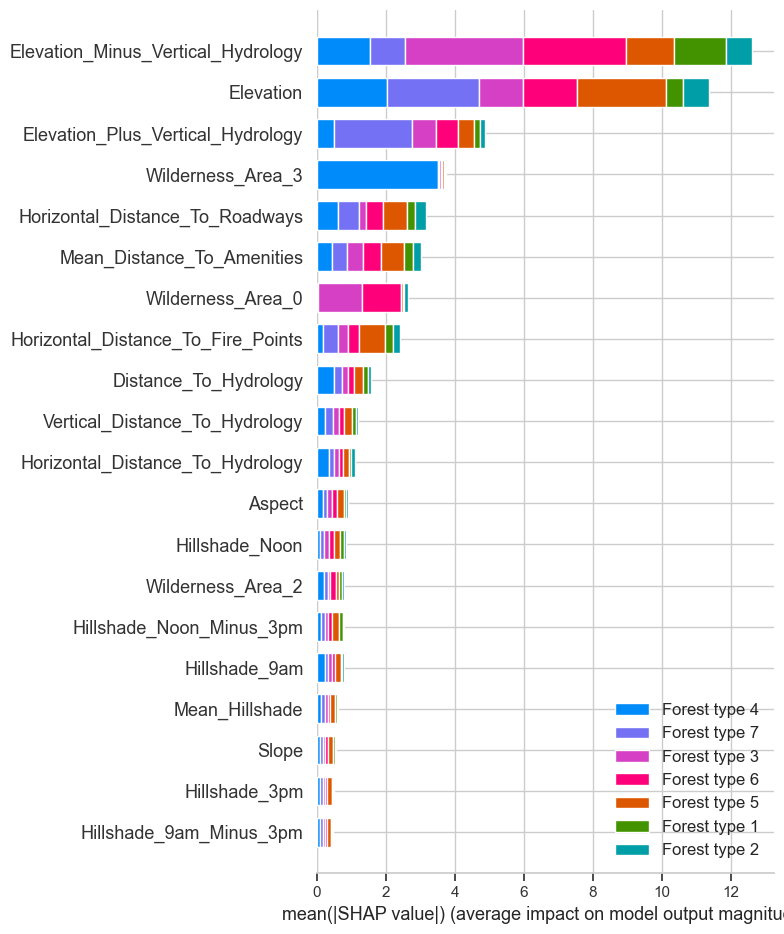

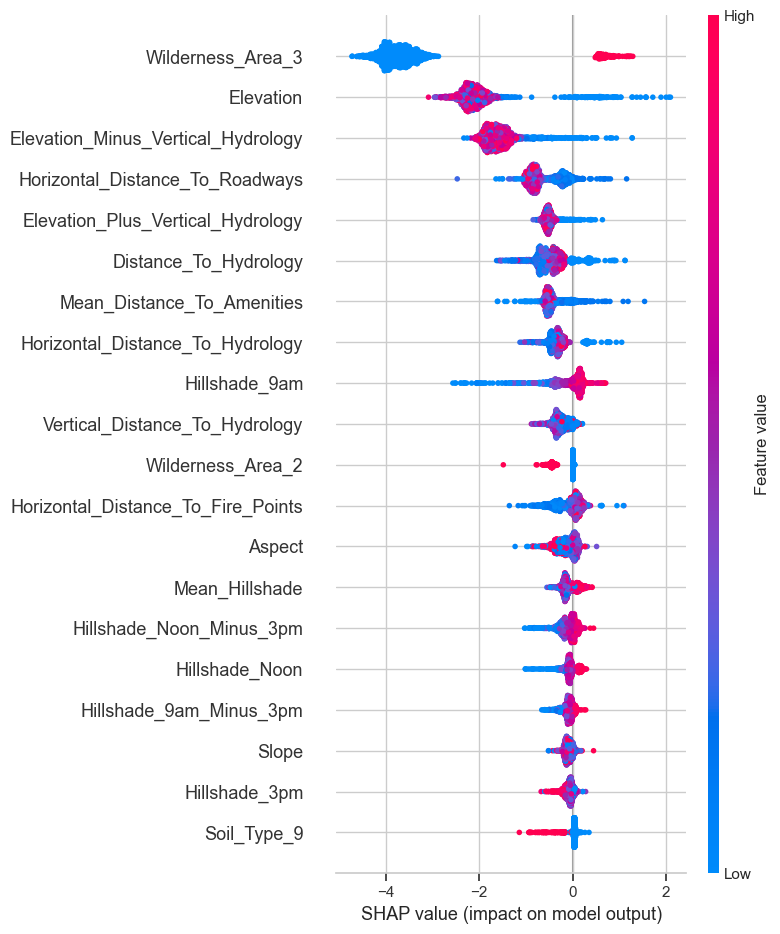

In [7]:
best_params = study.best_params
best_params.update({
    'objective': 'multi:softmax',
    'num_class': 7,
    'tree_method': 'hist',
    'random_state': 42,
    'n_jobs': -1,
    'n_estimators': 1000,
    'early_stopping_rounds': 15  
})

final_model = xgb.XGBClassifier(**best_params)

final_model.fit(
    X_train, y_train, 
    sample_weight=sample_weights_optuna,
    eval_set=[(X_val, y_val)],                   
    sample_weight_eval_set=[sample_weights_val], 
    verbose=False
)

print("Final Model Classification Report:\n")
y_pred_final = final_model.predict(X_test)
print(classification_report(y_test, y_pred_final, digits=4))

# 2. Shap analysis
X_shap_sample = X_test.sample(n=2000, random_state=42)

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_shap_sample)

# Formatting Shap array
if isinstance(shap_values, list):
    shap_values_3d = np.stack(shap_values, axis=-1)
else:
    shap_values_3d = shap_values

# Plot 1: Global importance of features
shap_values_list = shap_values if isinstance(shap_values, list) else [shap_values[:, :, i] for i in range(shap_values.shape[2])]

shap.summary_plot(
    shap_values_list, 
    X_shap_sample, 
    plot_type="bar", 
    class_names=[f"Forest type {i+1}" for i in range(7)]
)

# Plot 2: Feature's influence on rare class
shap_class_4 = shap_values_list[3]
shap.summary_plot(shap_class_4, X_shap_sample)

In [8]:
final_model.save_model("covtype_xgboost_model.json")